### Experiment 7: Gaussian Naive Bayes (Manual vs. Scikit-Learn)
We will train and compare a manual implementation of Gaussian Naive Bayes with scikit-learn's `GaussianNB` on our vectorized spam/ham dataset.

--- Dataset Overview ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB
None

--- Class Count Distribution ---
spam
0    4360
1    1368
Name: count, dtype: int64

--- Descriptive Statistics by Class ---


char_length                                                           \
           count         mean          std   min     25%     50%      75%   
spam                                                                        
0         4360.0  1631.918119  1959.664549  13.0  577.75  1122.0  2037.25   
1         1368.0  1317.257310  2271.372893  18.0  401.50   693.5  1250.25   

              word_count                                                     \
          max      count        mean         std  min    25%    50%     75%   
spam                                                                          
0     43952.0     4360.0  345.804817  406.189568  2.0  119.0  239.0  439.25   
1     28432.0     1368.0  266.432749  451.461674  4.0   79.0  139.5  251.00   

              
         max  
spam          
0     8477.0  
1     6129.0

/tmp/ipykernel_1257/2386326558.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Ham (0)', 'Spam (1)'])


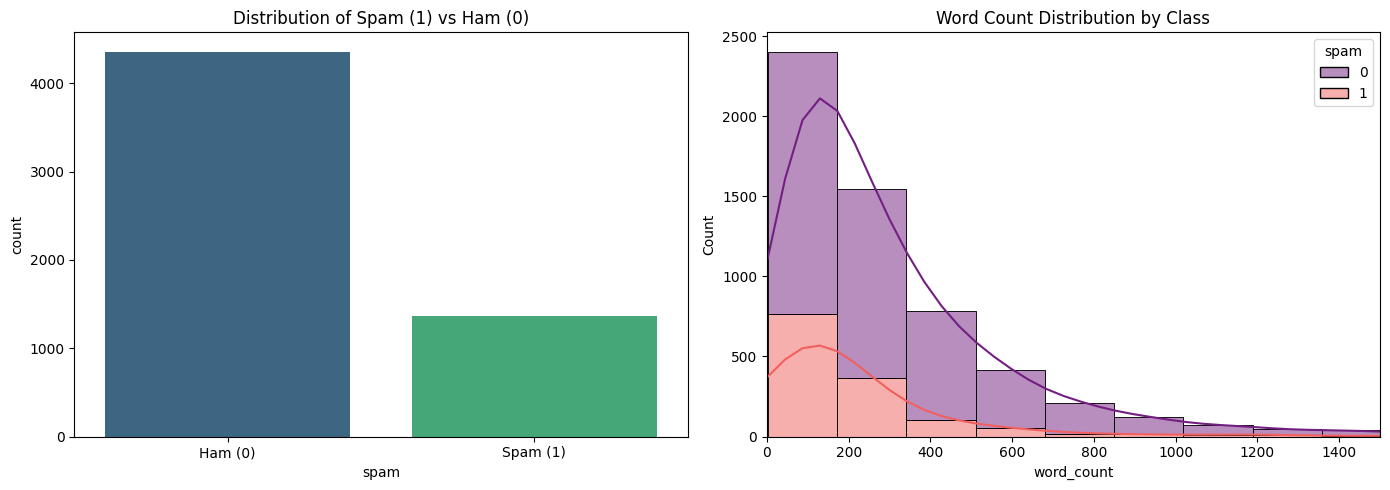

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load data
df_emails = pd.read_csv('/content/emails.csv')

# 2. Basic dataset statistics
print("--- Dataset Overview ---")
print(df_emails.info())
print("\n--- Class Count Distribution ---")
print(df_emails['spam'].value_counts())

# 3. Add text length metrics for analysis
df_emails['char_length'] = df_emails['text'].apply(len)
df_emails['word_count'] = df_emails['text'].apply(lambda x: len(x.split()))
print("\n--- Descriptive Statistics by Class ---")
display(df_emails.groupby('spam')[['char_length', 'word_count']].describe())

# 4. Visualization of Class Balance and Text Length
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_emails, x='spam', ax=axes[0], palette='viridis', hue='spam', legend=False)
axes[0].set_title('Distribution of Spam (1) vs Ham (0)')
axes[0].set_xticklabels(['Ham (0)', 'Spam (1)'])

sns.histplot(data=df_emails, x='word_count', hue='spam', kde=True, ax=axes[1], palette='magma', multiple='stack', bins=50)
axes[1].set_title('Word Count Distribution by Class')
axes[1].set_xlim([0, 1500])  # crop outliers for visualization clarity

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# 1. Manual Implementation of Gaussian Naive Bayes
class ManualGaussianNB:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.parameters = []
        for i, c in enumerate(self.classes):
            X_c = X[y == c]
            self.parameters.append({
                "mean": X_c.mean(axis=0),
                "var": X_c.var(axis=0) + 1e-9,  # avoid division by zero
                "prior": X_c.shape[0] / float(X.shape[0])
            })

    def _pdf(self, class_idx, x):
        mean = self.parameters[class_idx]["mean"]
        var = self.parameters[class_idx]["var"]
        numerator = np.exp(- (x - mean)**2 / (2 * var))
        denominator = np.sqrt(2 * np.pi * var)
        return numerator / denominator

    def predict(self, X):
        predictions = []
        for x in X:
            posteriors = []
            for i, c in enumerate(self.classes):
                prior = np.log(self.parameters[i]["prior"])
                # Sum of log likelihoods to prevent floating-point underflow
                conditional = np.sum(np.log(self._pdf(i, x) + 1e-9))
                posterior = prior + conditional
                posteriors.append(posterior)
            predictions.append(self.classes[np.argmax(posteriors)])
        return np.array(predictions)

# Train & Evaluate Manual Model
print("--- Manual Gaussian Naive Bayes ---")
manual_gnb = ManualGaussianNB()
manual_gnb.fit(X_train, y_train)
# Evaluate on a subset of test features for speed
manual_preds = manual_gnb.predict(X_test[:200])
print(f"Manual GNB Accuracy (on 200 samples): {accuracy_score(y_test[:200], manual_preds):.4f}")

# Train & Evaluate Scikit-Learn Model
print("\n--- Scikit-Learn Gaussian Naive Bayes ---")
sk_gnb = GaussianNB()
sk_gnb.fit(X_train, y_train)
sk_preds = sk_gnb.predict(X_test)
print(f"Scikit-Learn GNB Accuracy (full test): {accuracy_score(y_test, sk_preds):.4f}")
print(classification_report(y_test, sk_preds))

--- Manual Gaussian Naive Bayes ---
Manual GNB Accuracy (on 200 samples): 0.4700

--- Scikit-Learn Gaussian Naive Bayes ---
Scikit-Learn GNB Accuracy (full test): 0.9764
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       856
           1       0.95      0.96      0.95       290

    accuracy                           0.98      1146
   macro avg       0.97      0.97      0.97      1146
weighted avg       0.98      0.98      0.98      1146



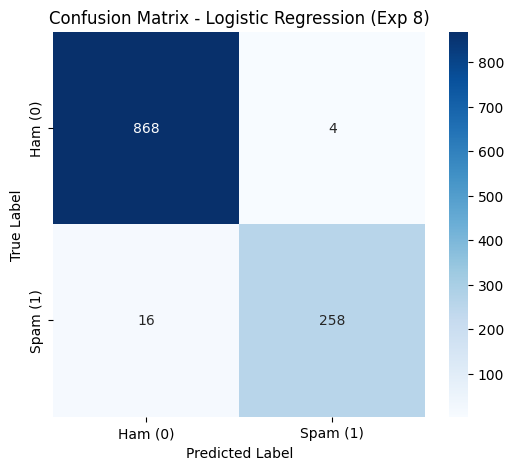

In [17]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrix for Exp 8
cm_8 = confusion_matrix(y_test_8, y_pred_8)

# Visualize the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm_8, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham (0)', 'Spam (1)'], yticklabels=['Ham (0)', 'Spam (1)'])
plt.title('Confusion Matrix - Logistic Regression (Exp 8)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

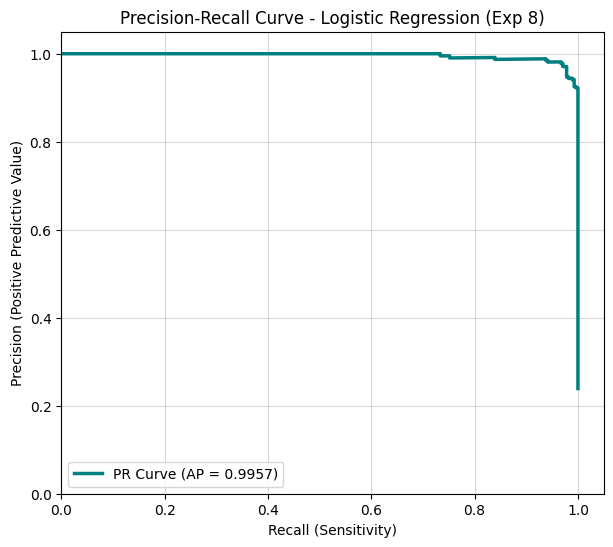

In [18]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Compute precision-recall pairs for different thresholds
precision, recall, thresholds_pr = precision_recall_curve(y_test_8, y_prob_8)
average_precision = average_precision_score(y_test_8, y_prob_8)

# Plot the Precision-Recall Curve
plt.figure(figsize=(7, 6))
plt.plot(recall, precision, color='teal', lw=2.5, label=f'PR Curve (AP = {average_precision:.4f})')
plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Precision (Positive Predictive Value)')
plt.title('Precision-Recall Curve - Logistic Regression (Exp 8)')
plt.xlim([0.0, 1.05])
plt.ylim([0.0, 1.05])
plt.grid(True, alpha=0.5)
plt.legend(loc='lower left')
plt.show()

exp 8

### Experiment 8: Logistic Regression for Binary Classification
In this section, we load, analyze, and prepare the dataset specifically for Logistic Regression. We will visualize the sigmoid function, decision boundary, and analyze the model performance using ROC and AUC metrics.

--- Dataset Shape ---
(5728, 2)

--- Class distribution ---
spam
0    0.761173
1    0.238827
Name: proportion, dtype: float64


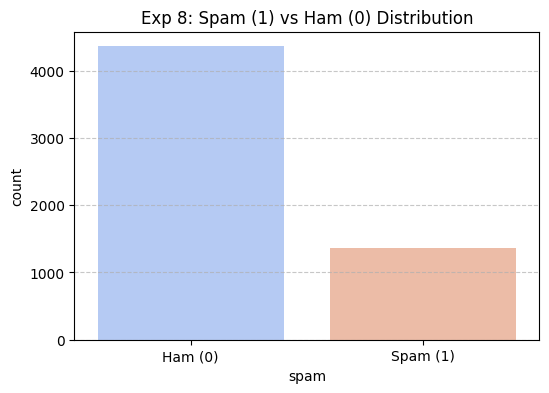

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, classification_report, accuracy_score

# 1. Load the dataset specifically for Exp 8
df_exp8 = pd.read_csv('/content/emails.csv')

# 2. Dataset overview & class analysis
print("--- Dataset Shape ---")
print(df_exp8.shape)
print("\n--- Class distribution ---")
print(df_exp8['spam'].value_counts(normalize=True))

# 3. Quick visualization of class distributions
plt.figure(figsize=(6, 4))
sns.countplot(data=df_exp8, x='spam', palette='coolwarm', hue='spam', legend=False)
plt.title('Exp 8: Spam (1) vs Ham (0) Distribution')
plt.xticks([0, 1], ['Ham (0)', 'Spam (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [14]:
# Vectorize the text data
vectorizer = TfidfVectorizer(max_features=3000)
X_vect = vectorizer.fit_transform(df_exp8['text']).toarray()
y_vect = df_exp8['spam'].values

# Train-test split
X_train_8, X_test_8, y_train_8, y_test_8 = train_test_split(X_vect, y_vect, test_size=0.2, random_state=42, stratify=y_vect)

# Train Logistic Regression
lr_model_8 = LogisticRegression(max_iter=1000, random_state=42)
lr_model_8.fit(X_train_8, y_train_8)

# Predict probabilities & labels
y_prob_8 = lr_model_8.predict_proba(X_test_8)[:, 1]
y_pred_8 = lr_model_8.predict(X_test_8)

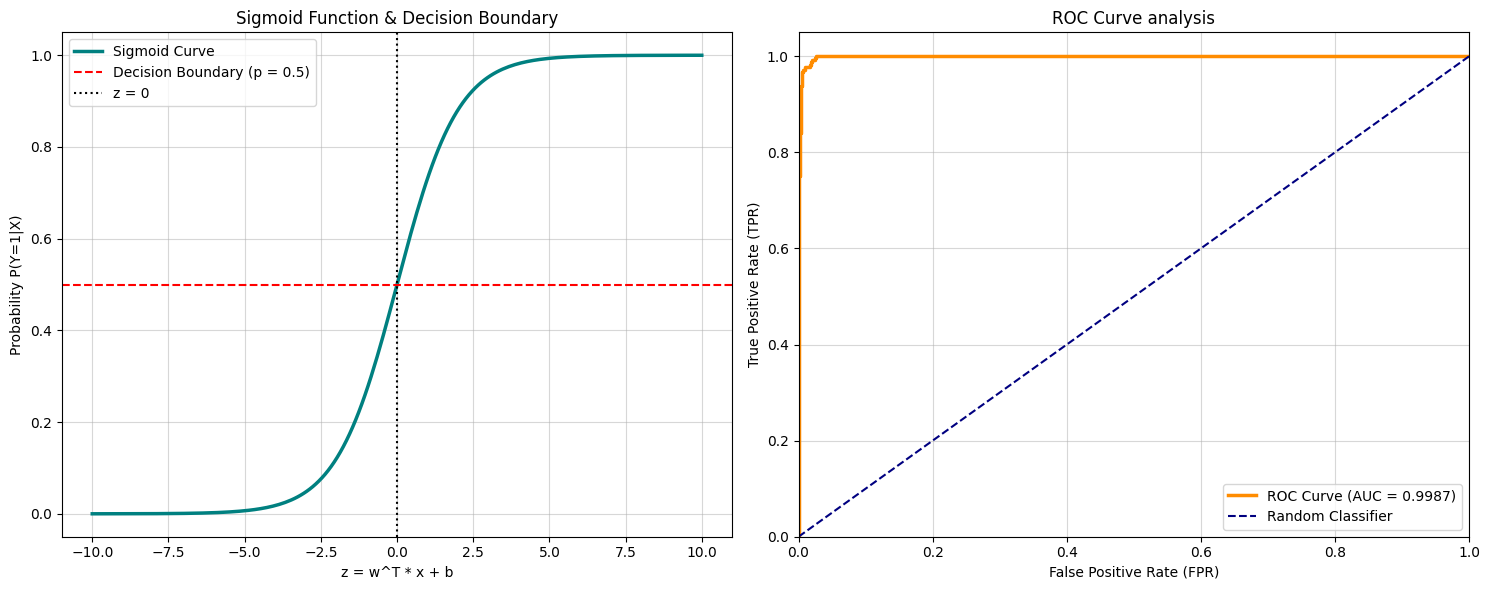


--- Classification Report ---
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       872
           1       0.98      0.94      0.96       274

    accuracy                           0.98      1146
   macro avg       0.98      0.97      0.98      1146
weighted avg       0.98      0.98      0.98      1146



In [15]:
# Visualizing the Sigmoid Function, Decision Boundary, and ROC/AUC
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left Plot: Sigmoid and Decision Boundary
z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))
axes[0].plot(z, sigmoid, label='Sigmoid Curve', color='teal', linewidth=2.5)
axes[0].axhline(0.5, color='red', linestyle='--', label='Decision Boundary (p = 0.5)')
axes[0].axvline(0, color='black', linestyle=':', label='z = 0')
axes[0].set_title('Sigmoid Function & Decision Boundary')
axes[0].set_xlabel('z = w^T * x + b')
axes[0].set_ylabel('Probability P(Y=1|X)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.5)

# Right Plot: ROC Curve & AUC
fpr_8, tpr_8, _ = roc_curve(y_test_8, y_prob_8)
roc_auc_8 = auc(fpr_8, tpr_8)

axes[1].plot(fpr_8, tpr_8, color='darkorange', lw=2.5, label=f'ROC Curve (AUC = {roc_auc_8:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Classifier')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].set_title('ROC Curve analysis')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

# Print metrics report
print("\n--- Classification Report ---")
print(classification_report(y_test_8, y_pred_8))

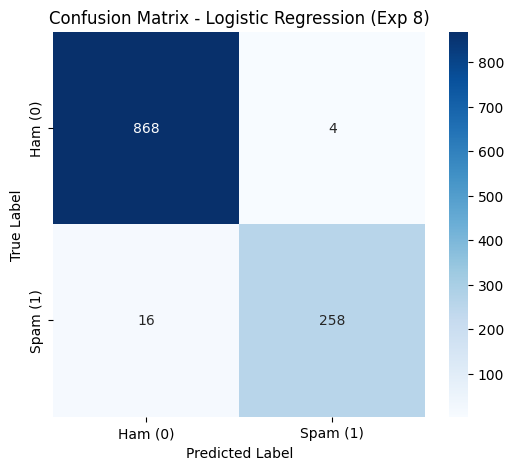

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(y_test_8, y_pred_8)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham (0)', 'Spam (1)'], yticklabels=['Ham (0)', 'Spam (1)'])
plt.title('Confusion Matrix - Logistic Regression (Exp 8)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

exp 9

--- Training Support Vector Machines (SVM) ---
Best Hyperparameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Score: 0.9884

--- Tuned SVM Test Set Performance ---
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       872
           1       0.97      0.98      0.98       274

    accuracy                           0.99      1146
   macro avg       0.98      0.99      0.99      1146
weighted avg       0.99      0.99      0.99      1146



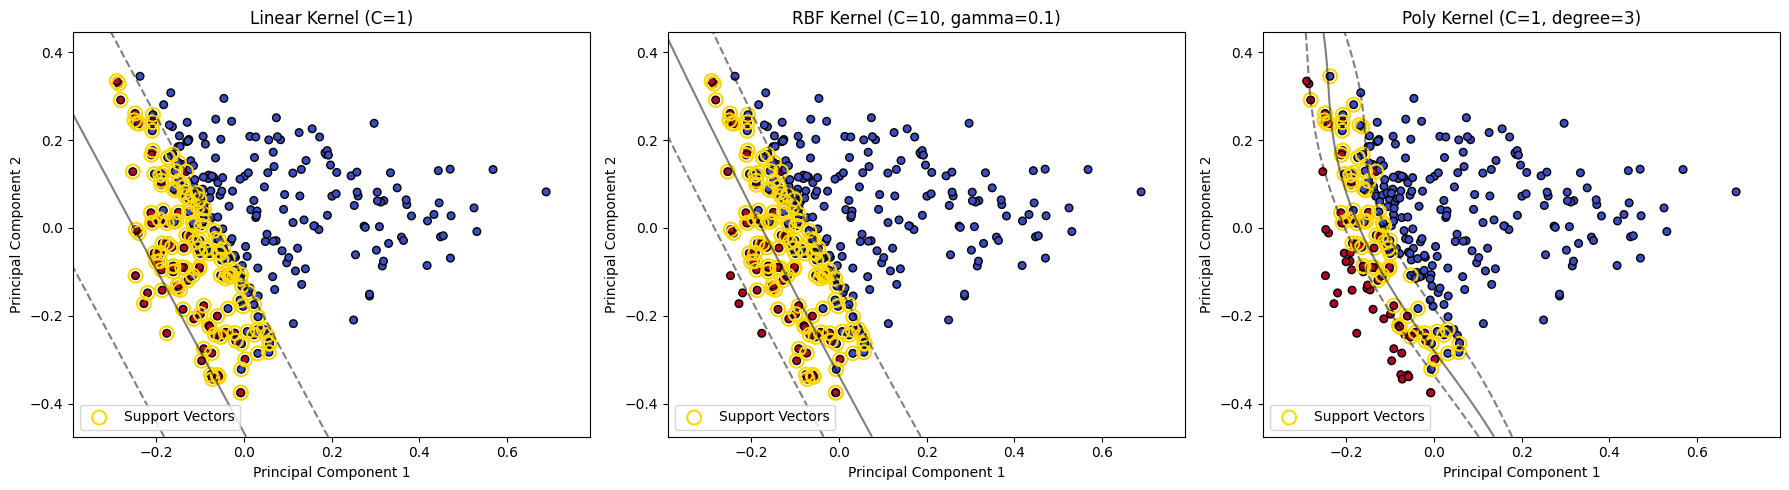

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, accuracy_score

# --- 1. Load Dataset & Vectorize for Experiment 9 ---
df_svm = pd.read_csv('/content/emails.csv')
vectorizer = TfidfVectorizer(max_features=1000) # Restricted features for SVM efficiency
X_vect = vectorizer.fit_transform(df_svm['text']).toarray()
y_vect = df_svm['spam'].values

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_vect, y_vect, test_size=0.2, random_state=42, stratify=y_vect
)

print("--- Training Support Vector Machines (SVM) ---")

# --- 2. Hyperparameter Tuning using Grid Search ---
# Define a parameter grid to tune C and gamma for Linear, RBF, and Poly SVMs
param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'], 'C': [1, 10], 'gamma': [0.1, 'scale']},
    {'kernel': ['poly'], 'degree': [3], 'C': [1, 10]}
]

grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Best CV Score: {grid_search.best_score_:.4f}")

# Evaluate the tuned model on the full test set
best_svm = grid_search.best_estimator_
y_pred = best_svm.predict(X_test)
print("\n--- Tuned SVM Test Set Performance ---")
print(classification_report(y_test, y_pred))

# --- 3. Visualize Margins, Support Vectors, and Decision Boundaries (2D Projection) ---
# Reduce the training data to 2D using PCA for visualization
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train)

# Subset data for plotting speed (take 300 samples)
subset_idx = np.random.choice(X_train_2d.shape[0], 300, replace=False)
X_vis = X_train_2d[subset_idx]
y_vis = y_train[subset_idx]

# Define SVM kernels to visualize on 2D
kernels = {
    'Linear Kernel (C=1)': SVC(kernel='linear', C=1),
    'RBF Kernel (C=10, gamma=0.1)': SVC(kernel='rbf', C=10, gamma=0.1),
    'Poly Kernel (C=1, degree=3)': SVC(kernel='poly', degree=3, C=1)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Create a mesh grid to plot decision boundary contours
x_min, x_max = X_vis[:, 0].min() - 0.1, X_vis[:, 0].max() + 0.1
y_min, y_max = X_vis[:, 1].min() - 0.1, X_vis[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

for ax, (title, clf) in zip(axes, kernels.items()):
    clf.fit(X_vis, y_vis)

    # Plot Decision boundary decision function
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot margins and boundary contours
    ax.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    # Scatter plot instances
    scatter = ax.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, s=30, cmap='coolwarm', edgecolors='k')

    # Highlight Support Vectors
    ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=100,
                linewidth=1.5, facecolors='none', edgecolors='gold', label='Support Vectors')

    ax.set_title(title)
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

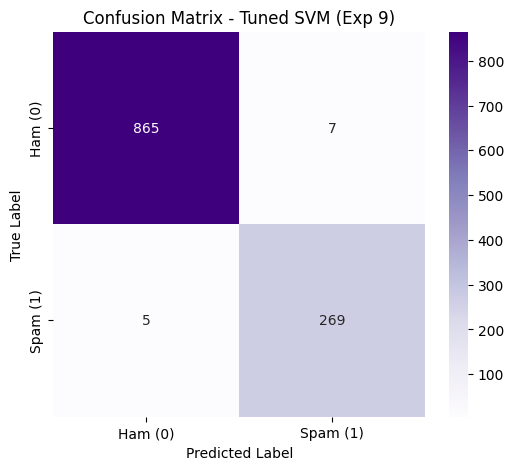

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute the confusion matrix for the best SVM model from Exp 9
cm_svm = confusion_matrix(y_test, y_pred)

# Plot the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Ham (0)', 'Spam (1)'],
    yticklabels=['Ham (0)', 'Spam (1)']
)
plt.title('Confusion Matrix - Tuned SVM (Exp 9)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()